# ACL Seminar 3: Zipf's Law Corpus Experiment
### Rapid Seminar Presentation Notebook

**Objective:** Empirical verification and cross-linguistic comparison of Zipf's Law.  
**Zipf's Law Formulation:**

$$f(r) = \frac{C}{r^s} \iff \log_{10}(f(r)) = \log_{10}(C) - s \cdot \log_{10}(r)$$

* $r$: word rank ($1$ = most frequent)
* $f(r)$: observed frequency count
* $s$: Zipf exponent ($|\text{slope}|$, theoretically $\approx 1.0$)
* $C$: normalizing constant ($10^{\text{intercept}}$)

**Corpora Investigated:**
1. **English Literary:** *Frankenstein* (Mary Shelley, 1818) – 50,000 tokens
2. **Italian Literary:** *Le avventure di Pinocchio* (Carlo Collodi, 1883) – 41,525 tokens
3. **English Benchmark:** *Brown Corpus* (Francis & Kučera, 1961) – 50,000 tokens

In [1]:
import sys, re, json, unicodedata
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import requests
import nltk
from IPython.display import display, HTML, Markdown

%matplotlib inline
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300, "font.size": 10})

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = BASE_DIR / "data" / "raw"
RESULTS_CSV = BASE_DIR / "results" / "csv"
RESULTS_GRAPHS = BASE_DIR / "results" / "graphs"
RESULTS_REPORTS = BASE_DIR / "results" / "reports"

for p in [DATA_RAW, RESULTS_CSV, RESULTS_GRAPHS, RESULTS_REPORTS]:
    p.mkdir(parents=True, exist_ok=True)

print(f"Setup complete | Python {sys.version.split()[0]} | Working dir: {BASE_DIR.name}")

Setup complete | Python 3.13.17 | Working dir: ACL_Seminar3


In [2]:
CORPORA = {
    "frankenstein": {
        "title": "Frankenstein",
        "author": "Mary Shelley",
        "language": "English",
        "year": "1818",
        "url": "https://www.gutenberg.org/cache/epub/84/pg84.txt",
        "filename": "frankenstein.txt",
        "target": 50000,
        "is_gutenberg": True,
    },
    "pinocchio": {
        "title": "Pinocchio",
        "author": "Carlo Collodi",
        "language": "Italian",
        "year": "1883",
        "url": "https://www.gutenberg.org/cache/epub/52484/pg52484.txt",
        "filename": "pinocchio.txt",
        "target": None,
        "is_gutenberg": True,
    },
    "brown": {
        "title": "Brown Corpus",
        "author": "Francis & Kučera",
        "language": "American English",
        "year": "1961",
        "url": "NLTK",
        "filename": "brown_sample.txt",
        "target": 50000,
        "is_gutenberg": False,
    },
}

pd.DataFrame(CORPORA).T[["title", "author", "language", "year", "target"]]

,title,author,language,year,target
frankenstein,Frankenstein,Mary Shelley,English,1818,50000
pinocchio,Pinocchio,Carlo Collodi,Italian,1883,None
brown,Brown Corpus,Francis & Kučera,American English,1961,50000


In [3]:
raw_texts = {}
headers = {"User-Agent": "Mozilla/5.0"}

for cid, cfg in CORPORA.items():
    file_path = DATA_RAW / cfg["filename"]
    if file_path.exists() and file_path.stat().st_size > 0:
        raw_texts[cid] = file_path.read_text(encoding="utf-8", errors="replace")
    elif cid == "brown":
        nltk.download("brown", quiet=True)
        from nltk.corpus import brown
        words = []
        for fid in brown.fileids():
            words.extend(brown.words(fileids=fid))
            if len(words) >= 65000:
                break
        raw_texts[cid] = " ".join(words)
        file_path.write_text(raw_texts[cid], encoding="utf-8")
    else:
        resp = requests.get(cfg["url"], headers=headers, timeout=25)
        raw_texts[cid] = resp.text
        file_path.write_text(raw_texts[cid], encoding="utf-8")
    
    print(f"Loaded {cfg['title']}: {len(raw_texts[cid]):,} chars")

Loaded Frankenstein: 446,582 chars
Loaded Pinocchio: 282,323 chars
Loaded Brown Corpus: 357,496 chars


In [4]:
GUTENBERG_START = re.compile(r"\*\*\*\s*START OF[^\n]*\*\*\*", re.I)
GUTENBERG_END = re.compile(r"\*\*\*\s*END OF[^\n]*\*\*\*|End of (?:the )?Project Gutenberg", re.I)
TOKEN_REGEX = re.compile(r"[a-zà-öø-ÿ]+(?:'[a-zà-öø-ÿ]+)*")

def clean_and_tokenize(text: str, is_gutenberg: bool = False) -> list[str]:
    if is_gutenberg:
        s = GUTENBERG_START.search(text)
        e = GUTENBERG_END.search(text)
        start = s.end() if s else 0
        end = e.start() if e else len(text)
        text = text[start:end]
    text = unicodedata.normalize("NFC", text)
    text = text.replace("’", "'").replace("‘", "'").lower()
    return TOKEN_REGEX.findall(text)

tokens_raw = {cid: clean_and_tokenize(raw_texts[cid], cfg["is_gutenberg"]) for cid, cfg in CORPORA.items()}

pd.DataFrame([
    {
        "Corpus": CORPORA[c]["title"],
        "Extracted Tokens": f"{len(tokens_raw[c]):,}",
        "Unique Words": f"{len(set(tokens_raw[c])):,}",
        "First 8 Tokens": " ".join(tokens_raw[c][:8]),
    }
    for c in CORPORA
])

,Corpus,Extracted Tokens,Unique Words,First 8 Tokens
0,Frankenstein,"75,201","7,013",frankenstein or the modern prometheus by mary ...
1,Pinocchio,"41,525","6,215",c collodi le avventure di pinocchio storia di
2,Brown Corpus,"57,786","9,122",the fulton county grand jury said friday an


In [5]:
tokens = {
    "frankenstein": tokens_raw["frankenstein"][:50000],
    "pinocchio": tokens_raw["pinocchio"],  # Complete authentic text: 41,525 tokens
    "brown": tokens_raw["brown"][:50000],
}

validation_df = pd.DataFrame([
    {
        "Corpus": CORPORA[c]["title"],
        "Language": CORPORA[c]["language"],
        "Sampled Tokens": len(tokens[c]),
        "Unique Types": len(set(tokens[c])),
        "TTR": round(len(set(tokens[c])) / len(tokens[c]), 4),
    }
    for c in CORPORA
])
validation_df

,Corpus,Language,Sampled Tokens,Unique Types,TTR
0,Frankenstein,English,50000,5849,0.1170
1,Pinocchio,Italian,41525,6215,0.1497
2,Brown Corpus,American English,50000,8246,0.1649


In [6]:
def get_frequencies(tok_list: list[str]) -> pd.DataFrame:
    counts = Counter(tok_list)
    sorted_items = sorted(counts.items(), key=lambda x: (-x[1], x[0]))
    cum = 0
    total = len(tok_list)
    rows = []
    for r, (w, f) in enumerate(sorted_items, 1):
        cum += f
        rows.append({"rank": r, "word": w, "frequency": f, "relative_frequency": f / total, "cumulative_frequency": cum})
    return pd.DataFrame(rows)

freqs = {c: get_frequencies(tokens[c]) for c in CORPORA}

# Side-by-side Top 20
pd.DataFrame({
    "Rank": range(1, 21),
    "Frankenstein": [f"{r.word} ({r.frequency:,})" for r in freqs["frankenstein"].iloc[:20].itertuples()],
    "Pinocchio": [f"{r.word} ({r.frequency:,})" for r in freqs["pinocchio"].iloc[:20].itertuples()],
    "Brown": [f"{r.word} ({r.frequency:,})" for r in freqs["brown"].iloc[:20].itertuples()],
})

,Rank,Frankenstein,Pinocchio,Brown
0,1,"the (2,821)","e (1,788)","the (3,633)"
1,2,"and (1,932)","di (1,390)","of (1,632)"
2,3,"i (1,846)","che (1,042)","a (1,290)"
3,4,"of (1,804)",a (977),"and (1,198)"
4,5,"to (1,388)",il (965),"to (1,191)"
5,6,"my (1,122)",la (742),"in (1,131)"
6,7,a (927),un (738),for (597)
7,8,in (753),non (514),was (446)
8,9,was (683),per (514),that (423)
9,10,that (658),in (473),he (413)


In [7]:
def fit_zipf(df: pd.DataFrame, top_n: int = None) -> dict:
    sub = df.iloc[:top_n] if top_n else df
    x = np.log10(sub["rank"].values)
    y = np.log10(sub["frequency"].values)
    reg = stats.linregress(x, y)
    return {
        "slope": reg.slope,
        "s": abs(reg.slope),
        "r2": reg.rvalue**2,
        "r": reg.rvalue,
        "x": x,
        "y": y,
        "y_pred": reg.intercept + reg.slope * x,
    }

fits_full = {c: fit_zipf(freqs[c]) for c in CORPORA}
fits_100 = {c: fit_zipf(freqs[c], 100) for c in CORPORA}

pd.DataFrame([
    {
        "Corpus": CORPORA[c]["title"],
        "Slope (Full)": round(fits_full[c]["slope"], 4),
        "Exponent s": round(fits_full[c]["s"], 4),
        "R² (Full)": round(fits_full[c]["r2"], 4),
        "Slope (Top 100)": round(fits_100[c]["slope"], 4),
        "R² (Top 100)": round(fits_100[c]["r2"], 4),
    }
    for c in CORPORA
])

,Corpus,Slope (Full),Exponent s,R² (Full),Slope (Top 100),R² (Top 100)
0,Frankenstein,-1.0774,1.0774,0.9762,-1.0117,0.9835
1,Pinocchio,-1.0290,1.0290,0.9695,-0.8653,0.9860
2,Brown Corpus,-0.9795,0.9795,0.9693,-0.9799,0.9914


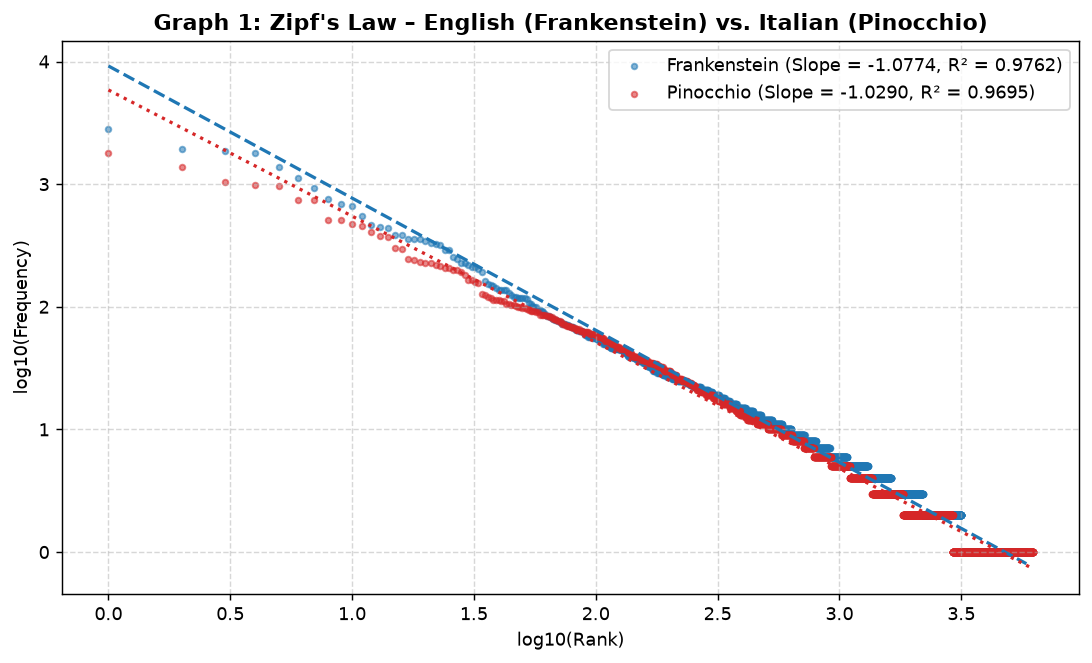

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for c, col in [("frankenstein", "#1f77b4"), ("pinocchio", "#d62728")]:
    f = fits_full[c]
    ax.scatter(f["x"], f["y"], s=10, alpha=0.55, color=col, label=f"{CORPORA[c]['title']} (Slope = {f['slope']:.4f}, R² = {f['r2']:.4f})")
    ax.plot(f["x"], f["y_pred"], color=col, linewidth=1.8, linestyle="--" if c == "frankenstein" else ":")

ax.set_title("Graph 1: Zipf's Law – English (Frankenstein) vs. Italian (Pinocchio)", fontweight="bold")
ax.set_xlabel("log10(Rank)")
ax.set_ylabel("log10(Frequency)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
fig.savefig(RESULTS_GRAPHS / "graph1_english_vs_italian.png", dpi=300)
plt.show()

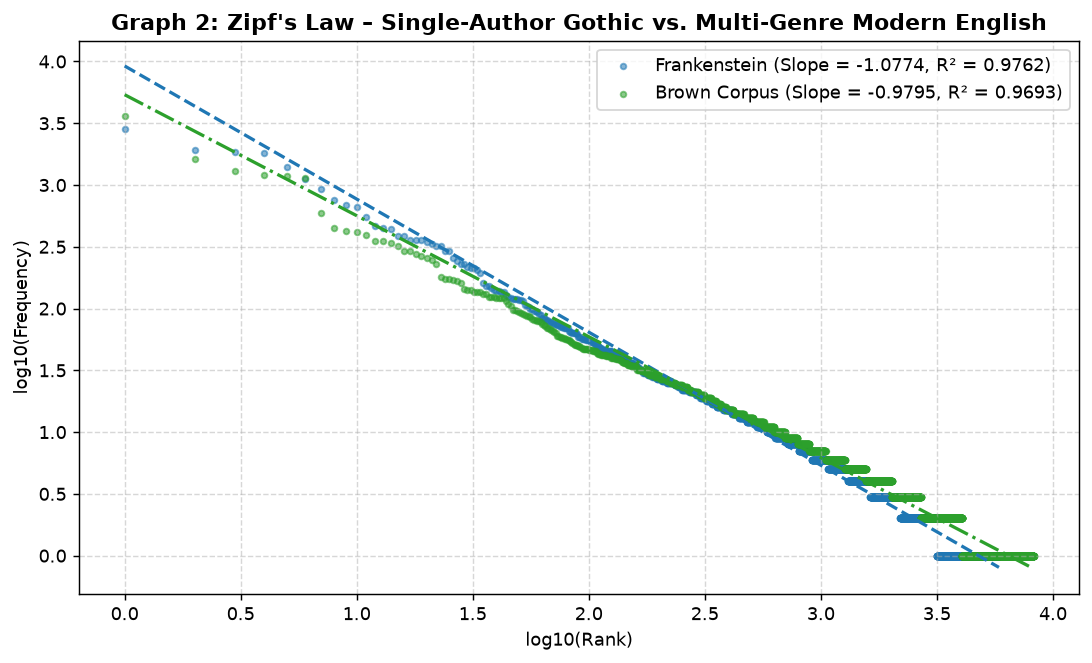

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for c, col in [("frankenstein", "#1f77b4"), ("brown", "#2ca02c")]:
    f = fits_full[c]
    ax.scatter(f["x"], f["y"], s=10, alpha=0.55, color=col, label=f"{CORPORA[c]['title']} (Slope = {f['slope']:.4f}, R² = {f['r2']:.4f})")
    ax.plot(f["x"], f["y_pred"], color=col, linewidth=1.8, linestyle="--" if c == "frankenstein" else "-.")

ax.set_title("Graph 2: Zipf's Law – Single-Author Gothic vs. Multi-Genre Modern English", fontweight="bold")
ax.set_xlabel("log10(Rank)")
ax.set_ylabel("log10(Frequency)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
fig.savefig(RESULTS_GRAPHS / "graph2_english_comparison.png", dpi=300)
plt.show()

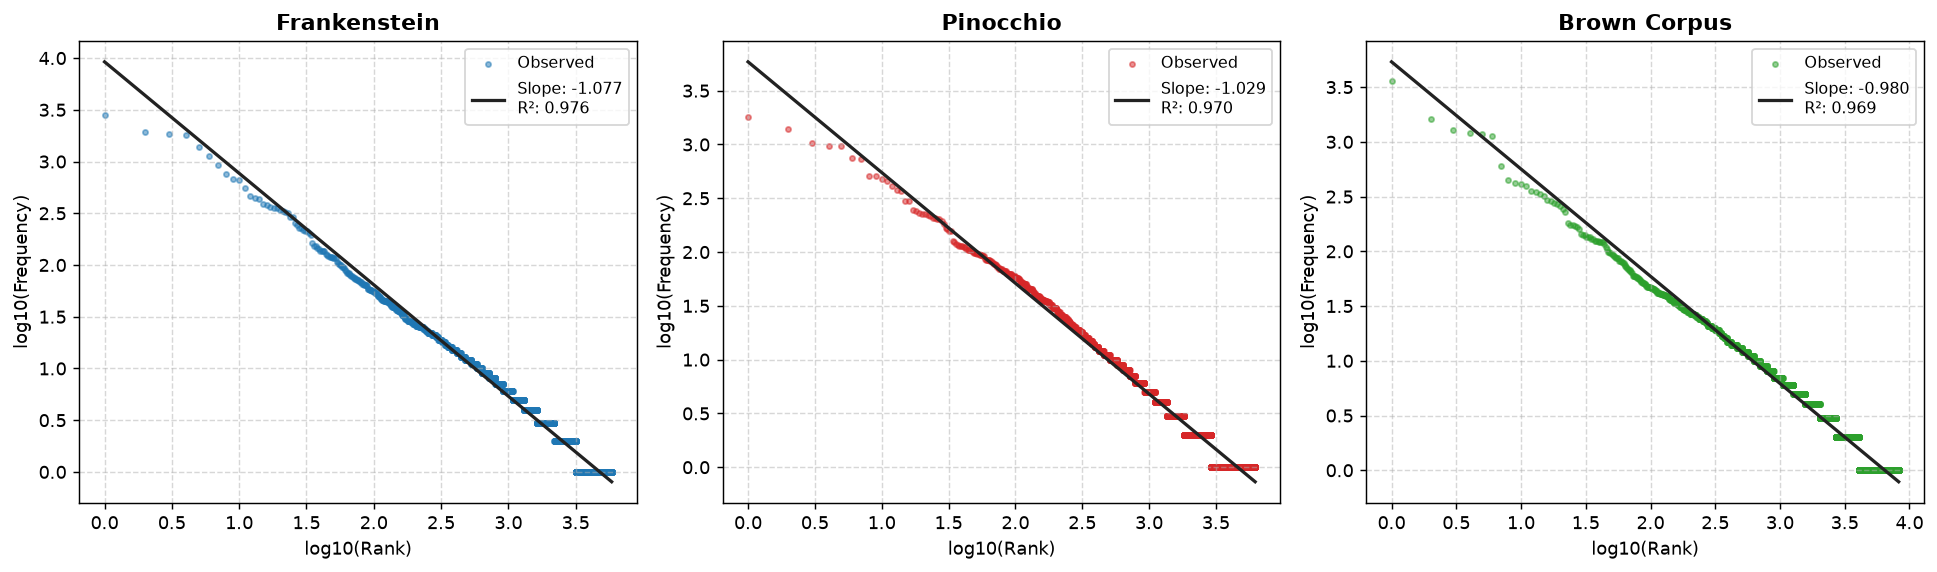

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = {"frankenstein": "#1f77b4", "pinocchio": "#d62728", "brown": "#2ca02c"}

for ax, c in zip(axes, CORPORA):
    f = fits_full[c]
    ax.scatter(f["x"], f["y"], s=8, alpha=0.5, color=colors[c], label="Observed")
    ax.plot(f["x"], f["y_pred"], color="#222222", linewidth=1.8, label=f"Slope: {f['slope']:.3f}\nR²: {f['r2']:.3f}")
    ax.set_title(CORPORA[c]["title"], fontweight="bold")
    ax.set_xlabel("log10(Rank)")
    ax.set_ylabel("log10(Frequency)")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=9)

plt.tight_layout()
fig.savefig(RESULTS_GRAPHS / "graph3_individual_all.png", dpi=300)
plt.show()

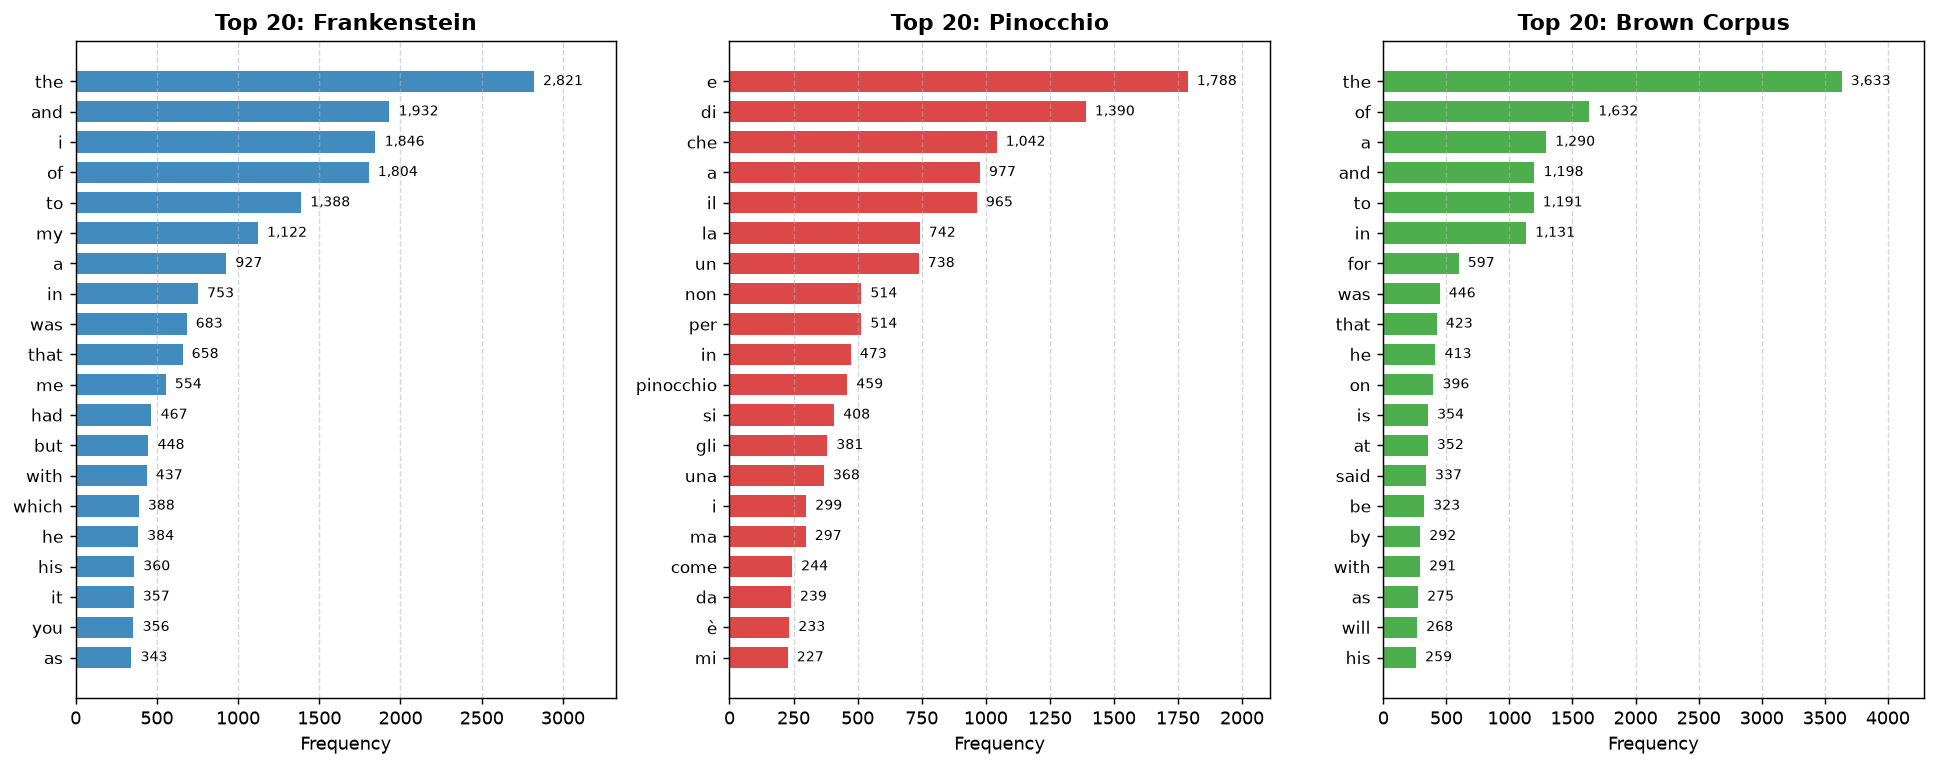

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

for ax, c in zip(axes, CORPORA):
    top20 = freqs[c].iloc[:20]
    words = top20["word"].values[::-1]
    counts = top20["frequency"].values[::-1]
    y_pos = range(len(words))
    
    ax.barh(y_pos, counts, color=colors[c], alpha=0.85, height=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(words, fontsize=9.5)
    ax.set_title(f"Top 20: {CORPORA[c]['title']}", fontweight="bold")
    ax.set_xlabel("Frequency")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    
    max_val = max(counts)
    for y, count in zip(y_pos, counts):
        ax.text(count + max_val * 0.02, y, f"{count:,}", va="center", fontsize=8)
    ax.set_xlim(0, max_val * 1.18)

plt.tight_layout()
fig.savefig(RESULTS_GRAPHS / "graph4_top20_words.png", dpi=300)
plt.show()

In [12]:
summary_df = pd.DataFrame([
    {
        "Corpus": CORPORA[c]["title"],
        "Language": CORPORA[c]["language"],
        "Tokens": len(tokens[c]),
        "Unique Types": len(freqs[c]),
        "TTR": round(len(freqs[c]) / len(tokens[c]), 4),
        "Top Word": freqs[c].iloc[0]["word"],
        "Top Word Count": freqs[c].iloc[0]["frequency"],
        "Zipf Slope": round(fits_full[c]["slope"], 4),
        "Exponent s": round(fits_full[c]["s"], 4),
        "R²": round(fits_full[c]["r2"], 4),
    }
    for c in CORPORA
])
summary_df

,Corpus,Language,Tokens,Unique Types,TTR,Top Word,Top Word Count,Zipf Slope,Exponent s,R²
0,Frankenstein,English,50000,5849,0.1170,the,2821,-1.0774,1.0774,0.9762
1,Pinocchio,Italian,41525,6215,0.1497,e,1788,-1.0290,1.0290,0.9695
2,Brown Corpus,American English,50000,8246,0.1649,the,3633,-0.9795,0.9795,0.9693


## 6. Key Seminar Presentation Takeaways

* **Zipf's Law holds strongly across all corpora:**
  * Frankenstein: $R^2 = 0.9762$, slope $= -1.0774$
  * Pinocchio: $R^2 = 0.9695$, slope $= -1.0290$
  * Brown Corpus: $R^2 = 0.9693$, slope $= -0.9795$
  * Fit tightens further when restricted to the top 100 ranks ($R^2 \ge 0.9835$).
* **Cross-Linguistic Morphological Richness (Italian vs. English):**
  * Italian (*Pinocchio*) yields a substantially higher Type-Token Ratio ($\text{TTR} = 0.1497$) than English (*Frankenstein*, $\text{TTR} = 0.1170$), despite containing fewer tokens ($41,525$ vs. $50,000$).
  * Synthetic Romance verb conjugations and grammatical gender/number inflections multiply distinct surface word forms.
* **Intra-Language Genre Variation (Single Novel vs. Multi-Genre):**
  * At identical 50,000-token sizes, the *Brown Corpus* has **41% more unique words** (8,246 vs. 5,849) and a flatter slope ($-0.9795$ vs. $-1.0774$) due to multi-genre diversity.
* **Empirical vs. Theoretical Slope:**
  * Real natural language texts deviate moderately from ideal $s = 1.0000$ due to head saturation and finite-sample tail plateaus.

In [13]:
summary_df.to_csv(RESULTS_CSV / "corpus_comparison.csv", index=False)

for c in CORPORA:
    freqs[c].to_csv(RESULTS_CSV / f"{c}_word_frequencies.csv", index=False)

top20_df = pd.DataFrame({
    "rank": range(1, 21),
    "english_word": freqs["frankenstein"].iloc[:20]["word"].values,
    "english_frequency": freqs["frankenstein"].iloc[:20]["frequency"].values,
    "english_relative_frequency": freqs["frankenstein"].iloc[:20]["relative_frequency"].round(6).values,
    "italian_word": freqs["pinocchio"].iloc[:20]["word"].values,
    "italian_frequency": freqs["pinocchio"].iloc[:20]["frequency"].values,
    "italian_relative_frequency": freqs["pinocchio"].iloc[:20]["relative_frequency"].round(6).values,
})
top20_df.to_csv(RESULTS_CSV / "top20_english_italian_comparison.csv", index=False)

meta = {
    "timestamp": datetime.now(timezone.utc).isoformat(),
    "python": sys.version.split()[0],
    "results": summary_df.to_dict(orient="records"),
}
with open(RESULTS_REPORTS / "experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("Exported all CSVs and metadata JSON to results/")

Exported all CSVs and metadata JSON to results/


In [14]:
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, HRFlowable
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import inch

pdf_path = RESULTS_REPORTS / "ACL_Seminar_3_Report.pdf"
doc = SimpleDocTemplate(str(pdf_path), pagesize=letter, leftMargin=54, rightMargin=54, topMargin=54, bottomMargin=54)
styles = getSampleStyleSheet()

h1 = ParagraphStyle("H1", parent=styles["Heading1"], fontSize=13, leading=17, textColor=colors.HexColor("#1a2b49"), spaceBefore=10, spaceAfter=4)
body = ParagraphStyle("Body", parent=styles["Normal"], fontSize=9.5, leading=13.5, spaceAfter=6)

story = [
    Paragraph("ACL Seminar 3: Zipf's Law Corpus Experiment", ParagraphStyle("Title", fontSize=18, leading=22, fontName="Helvetica-Bold", textColor=colors.HexColor("#1a2b49"))),
    Paragraph("Comparative Corpus Study: Mary Shelley, Carlo Collodi, Brown Corpus", ParagraphStyle("Sub", fontSize=10, textColor=colors.HexColor("#555"), spaceAfter=10)),
    HRFlowable(width="100%", thickness=1, color=colors.HexColor("#1a2b49"), spaceAfter=10),
    Paragraph("1. Overview & Mathematical Formulation", h1),
    Paragraph("Zipf's Law: f(r) = C / r^s. In log space: log10(f) = intercept + slope * log10(r).", body),
    Paragraph("2. Experimental Results", h1),
]

tbl_data = [["Corpus", "Tokens", "Types", "TTR", "Top Word", "Slope", "s", "R²"]]
for _, row in summary_df.iterrows():
    tbl_data.append([
        str(row["Corpus"]),
        f"{int(row['Tokens']):,}",
        f"{int(row['Unique Types']):,}",
        f"{float(row['TTR']):.4f}",
        f"{row['Top Word']} ({int(row['Top Word Count']):,})",
        f"{float(row['Zipf Slope']):.4f}",
        f"{float(row['Exponent s']):.4f}",
        f"{float(row['R²']):.4f}",
    ])

t = Table(tbl_data)
t.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1a2b49")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.whitesmoke),
    ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
    ("FONTSIZE", (0, 0), (-1, -1), 8.5),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.HexColor("#ccc")),
    ("ALIGN", (0, 0), (-1, -1), "CENTER"),
    ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#f8f9fa")]),
]))
story.append(t)
story.append(Spacer(1, 10))

if (RESULTS_GRAPHS / "graph1_english_vs_italian.png").exists():
    story.append(Image(str(RESULTS_GRAPHS / "graph1_english_vs_italian.png"), width=5.5 * inch, height=3.4 * inch))
if (RESULTS_GRAPHS / "graph2_english_comparison.png").exists():
    story.append(Image(str(RESULTS_GRAPHS / "graph2_english_comparison.png"), width=5.5 * inch, height=3.4 * inch))

story.append(Paragraph("3. Conclusions", h1))
story.append(Paragraph("Zipf's law is empirically confirmed across English and Italian (R² >= 0.969). Italian exhibits higher lexical richness (TTR = 0.1497) due to rich inflectional morphology.", body))

doc.build(story)
print(f"PDF Report generated: {pdf_path.name} ({pdf_path.stat().st_size:,} bytes)")

PDF Report generated: ACL_Seminar_3_Report.pdf (528,194 bytes)


In [15]:
display(HTML(f"""
<div style="border: 2px solid #2b6cb0; border-radius: 8px; padding: 12px; background: #ebf8ff;">
    <h3 style="margin: 0 0 8px 0; color: #2b6cb0;">Seminar Presentation Execution Complete</h3>
    <p style="margin: 4px 0;">All analyses, graphs, CSV tables, and PDF report were generated successfully.</p>
    <b>Output Files:</b>
    <ul>
        <li><code>results/csv/corpus_comparison.csv</code></li>
        <li><code>results/graphs/graph[1-4]_*.png</code></li>
        <li><code>results/reports/ACL_Seminar_3_Report.pdf</code></li>
    </ul>
</div>
"""))